A notebook to test the functions of the new vrdr_resampler Python module.

In [1]:
# auto reload
%load_ext autoreload
%autoreload 2

In [2]:
import vrdr_resampler as vrdr
from pathlib import Path

# OROCHI Observations of Mars

OROCHI is the VNIR multispectral imager for the MMX sample return mission to Phobos and Deimos. OROCHI will also image the Mars surface from the Phobos orbit, at a near stable altitude of 6000 km.

Plans for MMX observations of Mars, including with OROCHI, are given by [Ogohara et al 2022](https://doi.org/10.1186/s40623-021-01417-0).

OROCHI has an FoV of $\gtrsim$ 1 rad, and an iFoV of 0.4 mrad, that can capture the entire Mars disk, with a pixel resolution of 2.4 km/pixel.

OROCHI has 7 unique bands: 390 nm, 480 nm, 550 nm, 650 nm, 730 nm, 860 nm and 950 nm.

The Blue and Red bands will be used to monitor atmospheric dynamics, and distinguish dust and water ice clouds. The 950 nm channel will be used to cross-calibrate observations with MIRS.

# Loading the OROCHI Spectral Response

Setting a string id for the instrument, that will prefixed to output files:

In [3]:
inst_id = 'o'

Setting the path to the instrument file:

In [4]:
# instrument path
inst_path = Path('instrument_response', 'mmx_orochi_system_response.csv')

Loading instrument transmission profiles:

In [5]:
orochi_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(orochi_data)

Checking the profile spectral range and resolution:

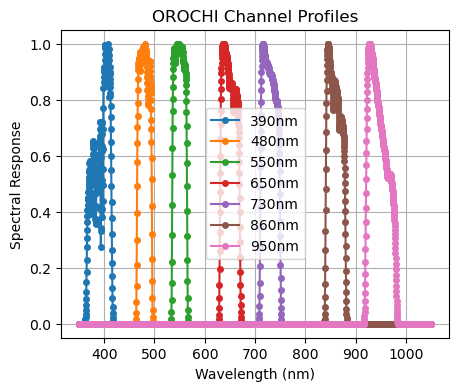

In [6]:
fig, ax = vrdr.plot_channel_profiles(orochi_data, instrument='OROCHI')

# Loading a VRDR Tile

Setting the data directory:

In [7]:
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr')

Setting the output directory:

In [8]:
output_path = vrdr_path.parent / 'vrdr_orochi'
output_path.mkdir(exist_ok=True) 

Finding the quadrant directories:

In [9]:
mc_paths = vrdr.get_quadrant_dirs(vrdr_path)
mc_path = mc_paths[0]  # Example: process the first quadrant directory

Finding the tile paths in the quadrant directory:

In [10]:
lbl_paths = vrdr.get_tile_lbls(mc_path)
lbl_path = lbl_paths[0]  # Example: process the first label file

Preparing the output file directory:

In [11]:
out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
out_dir

Output directory exists, overwriting:  /Volumes/RS_STORE/vrdr_orochi/mc16/t0623_vrral_25s183_0654_1


PosixPath('/Volumes/RS_STORE/vrdr_orochi/mc16/t0623_vrral_25s183_0654_1')

Loading the tile, getting the band centre-wavelengths, and the no-data value:

In [12]:
vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

# Resampling to the Spectral Response to an OROCHI I/F Cube

Resampling the VRDR Cube from the VRDR CWLs to the instrument bands:

In [13]:
band_cwls

array([393., 480., 550., 649., 729., 858., 945.])

In [14]:
oifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

In [15]:
# a function for resampling the spatial resolution of the cube.


# Exporting the I/F Cube

In [20]:
orochi_res = 2400.0 # new resolution in meters

In [22]:
out_file = vrdr.export_ifcub_geotiff(oifcub,band_list,band_cwls,no_data,inst_id,lbl_path,out_dir, new_resolution=orochi_res)
out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data,[7,4,2], inst_id, lbl_path, out_dir)

## Verifying the Resampling Method

Checking the interpolation of the band wavelengths to the VRDR CWLs:

In [27]:
b_w = arr_wvls
c_w = vrdr_cwls
b_a = band_arr
resampled_profiles = [vrdr.interp_band_profile(b_p, b_w, c_w) for b_p in b_a.T]

In [28]:
import numpy as np
import pandas as pd
resampled_inst = pd.DataFrame(data=np.array(resampled_profiles).T, columns=band_list, index=c_w)

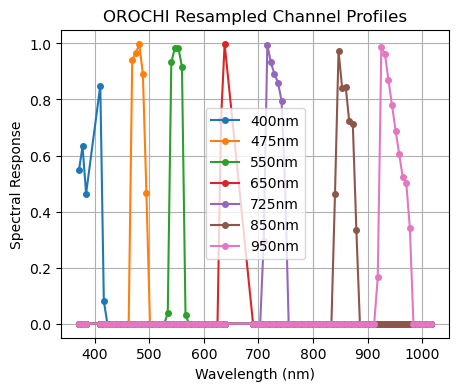

In [29]:
fig, ax = vrdr.plot_channel_profiles(resampled_inst, instrument='OROCHI Resampled')

Checking a random selection of VRDR tile spectra

/var/folders/d4/cz7hyt3n1_b1r1pbq06pffy9mjlwy3/T/ipykernel_38744/3004135867.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


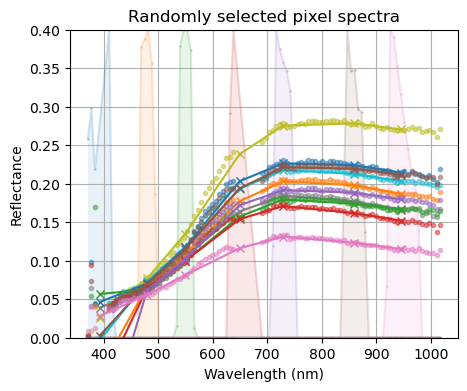

In [31]:
# select random locations in the last 2 dimensions of the cube
import random
import matplotlib.pyplot as plt

num_samples = 10
x_size, y_size = vrdr_cube.shape[1], vrdr_cube.shape[2]
random_coords = [(random.randint(0, x_size - 1), random.randint(0, y_size - 1)) for _ in range(num_samples)]

fig, ax = plt.subplots(figsize=(5, 4))

y_max = 0.4

for band in resampled_inst.columns:
    ax.plot(resampled_inst.index, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), label=band, linestyle='-',marker='o', alpha=0.2, markersize=1)
    # fill the area under each band profile
    ax.fill_between(resampled_inst.index, 0, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), alpha=0.1)

for x, y in random_coords:
    vrdr_spectrum = vrdr_cube[:, x, y]
    orochi_spectrum = oifcub[:, x, y]

    ax.plot(vrdr_cwls, vrdr_spectrum, label=f'{x,y}', marker='o', markersize=3, linestyle='None', alpha=0.5)
    # get colour used in the plot above
    color = ax.get_lines()[-1].get_color()
    ax.plot(band_cwls, orochi_spectrum, label=f'{x,y}', marker='x', markersize=6, color=color)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Reflectance')
# plt.legend()
ax.set_title(f'Randomly selected pixel spectra')
ax.set_ylim(0, y_max)
ax.grid()
fig.show()

Note that data points with wavelengths <400 nm (i.e. the apparently noisy channels) are 0-weighted by the CaSSIS BLU transmission, so they effectively are not counted.

# Prepare Products

## Setting OROCHI Browse Products and Spectral Parameters

In [23]:
band_cwls

array([393., 480., 550., 649., 729., 858., 945.])

In [25]:
band_cwls[6]

np.float64(945.0)

Import the instrument specific product class:

In [28]:
import orochi_products as orochi

## Spectral Parameter (or Summary Product) Stack

Make a stack of the spectral parameters:

In [30]:
ospcub, sp_ids = orochi.spectral_parameter_stack(oifcub, no_data)

Export the stack to a GeoTIFF:

In [31]:
vrdr.export_spcub_geotiff(ospcub,sp_ids,no_data,inst_id,lbl_path,out_dir)

PosixPath('/Volumes/RS_STORE/vrdr_orochi/mc16/t0623_vrral_25s183_0654_1/t0623_ospcub_25s183_0654_1.tif')

In [32]:
vrdr.write_spcub_envi_hdr(sp_ids, no_data, [3, 1, 2],inst_id,lbl_path,out_dir)

PosixPath('/Volumes/RS_STORE/vrdr_orochi/mc16/t0623_vrral_25s183_0654_1/t0623_ospcub_25s183_0654_1.hdr')

## Browse Products

Stretching the I/F Cube: stretching float I/F data to 8-bit unsigned int for efficient browse product storage involves stretching each channel.

The standard method for CaSSIS is to use percentile stretches, where the bottom 0.1% and the top 99.95% percentiles are used to set the clip values.

We log these stretch parameters.

In [33]:
st_cub, st_params = vrdr.stretch_cube(oifcub, no_data)

In [34]:
log_path = vrdr.log_st_params(st_params, band_list, lbl_path, out_dir)

In [36]:
from matplotlib import pyplot as plt

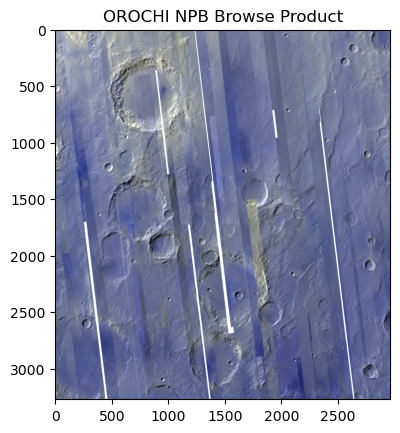

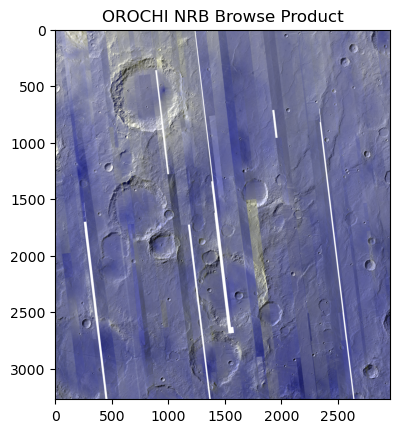

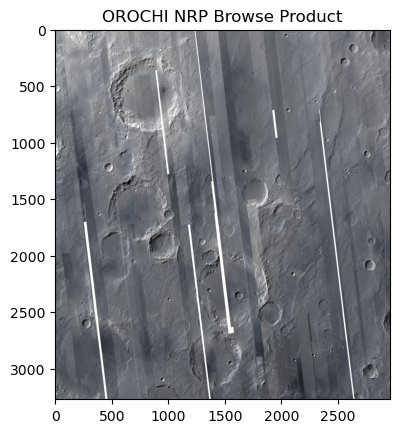

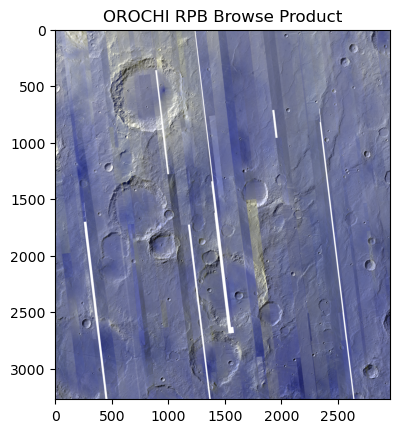

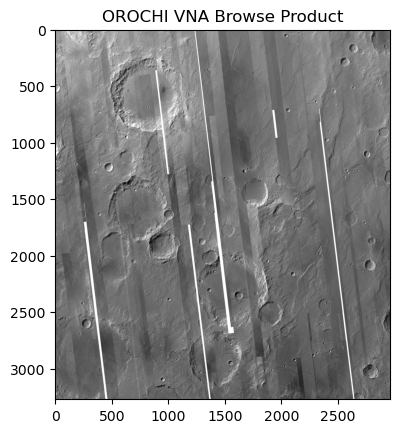

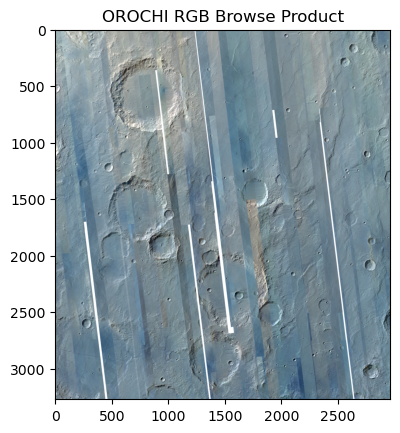

In [38]:
st_cub, st_params = vrdr.stretch_cube(oifcub, no_data)
for bp_id in orochi.BP_LIST:
    bp_func = orochi.browse_product(bp_id)
    bp, bp_bands = bp_func(st_cub)
    vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir)
    plt.imshow(bp)
    plt.title(f'OROCHI {bp_id} Browse Product')
    plt.show()

## Composite Spectral Parameter Browse Products

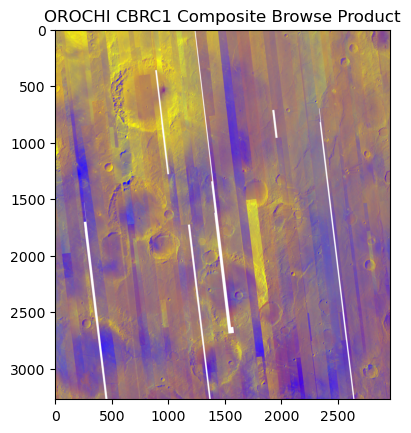

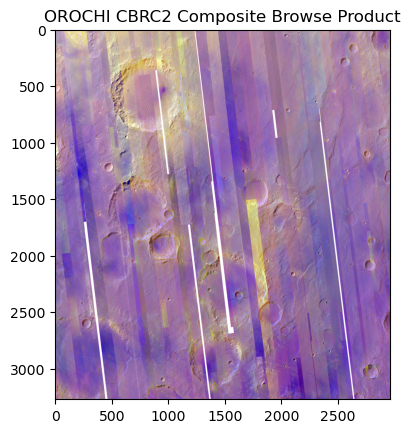

In [39]:
for cp_id in orochi.CP_LIST:
    cp_func = orochi.composite_product(cp_id)
    cp, cp_list = cp_func(oifcub, no_data)
    cp_st, st_params = vrdr.stretch_cube(cp, no_data)
    vrdr.export_bp_geotiff(cp_st.transpose((1, 2, 0)), cp_id, 255, cp_list, inst_id, lbl_path, out_dir)
    plt.imshow(cp_st.transpose((1, 2, 0)))
    plt.title(f'OROCHI {cp_id} Composite Browse Product')
    plt.show()

# Running the Loop

In [40]:
from tqdm.auto import tqdm

In [51]:
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr')
output_path = vrdr_path.parent / 'vrdr_orochi'
output_path.mkdir(exist_ok=True) 

inst_id = 'o'
inst_path = Path('instrument_response', 'mmx_orochi_system_response.csv')
orochi_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(orochi_data)

new_res = 2400.0  # OROCHI spatial resolution in meters

mc_paths = vrdr.get_quadrant_dirs(vrdr_path)
mc_paths = mc_paths[:3]
for mc_path in tqdm(mc_paths, desc='Quadrants'):
    # if mc_path.stem not in ['mc16']:
    #     continue
    print('Processing MC Directory: ', mc_path.name)
    # get lbl files but ignore hidden files
    lbl_paths = vrdr.get_tile_lbls(mc_path)
    # sort

    for lbl_path in tqdm(lbl_paths, desc=f'{mc_path.stem} Tiles'):
        print(' - ', lbl_path.stem)

        out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=False)
        if out_dir == Path():
            continue

        vrdr_cube, vrdr_wvls, no_data = vrdr.load_vrdr_tile(lbl_path)

        oifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_wvls, no_data)

        out_file = vrdr.export_ifcub_geotiff(oifcub, band_list, band_cwls, no_data, inst_id, lbl_path, out_dir, new_resolution=new_res)
        out_hdr = vrdr.write_ifcub_envi_hdr(band_list, band_cwls, no_data, [4, 2, 1], inst_id, lbl_path, out_dir)

        st_cub, st_params = vrdr.stretch_cube(oifcub, no_data)
        log_path = vrdr.log_st_params(st_params, band_list, lbl_path, out_dir)

        cspcub, sp_ids = orochi.spectral_parameter_stack(oifcub, no_data)
        vrdr.export_spcub_geotiff(cspcub,sp_ids,no_data,inst_id,lbl_path,out_dir, new_resolution=new_res)
        vrdr.write_spcub_envi_hdr(sp_ids, no_data, [3, 1, 2],inst_id,lbl_path,out_dir)
        
        st_cub, st_params = vrdr.stretch_cube(oifcub, no_data)
        for bp_id in orochi.BP_LIST:
            bp_func = orochi.browse_product(bp_id)
            bp, bp_bands = bp_func(st_cub)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir, new_resolution=new_res)

        for cp_id in orochi.CP_LIST:
            cp_func = orochi.composite_product(cp_id)
            cp, cp_list = cp_func(oifcub, no_data)
            cp_st, st_params = vrdr.stretch_cube(cp, no_data)
            vrdr.export_bp_geotiff(cp_st.transpose((1, 2, 0)), cp_id, 255, cp_list, inst_id, lbl_path, out_dir, new_resolution=new_res)
        

Quadrants:   0%|          | 0/3 [00:00<?, ?it/s]

Processing MC Directory:  mc16


mc16 Tiles:   0%|          | 0/54 [00:00<?, ?it/s]

 -  t0623_vrral_25s183_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0624_vrral_25s188_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0625_vrral_25s193_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0626_vrral_25s198_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666

mc17 Tiles:   0%|          | 0/54 [00:00<?, ?it/s]

 -  t0632_vrral_25s228_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0633_vrral_25s233_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0634_vrral_25s238_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0635_vrral_25s243_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666

mc18 Tiles:   0%|          | 0/54 [00:00<?, ?it/s]

 -  t0641_vrral_25s273_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0642_vrral_25s278_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0643_vrral_25s283_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666667
 -  t0644_vrral_25s288_0654_1
Scale factor: 0.03772421666666667
Scale factor: 0.03772421666666

Now I'd like a quick script that loops over all processed tiles in a quadrant, gets the quadrant-wide stretch parameters, and then makes a mosaic browse product at that level.

# Making Quadrant Wide Mosaics

Let's re-write this from scratch, now loading in the .log file from each porcessed mosaic, and putting the new stretch products in a dedicated new product directory (vrdr_cassis_quads).

In [54]:
# get orochi quadrant directory paths
vrdr_orochi_path = Path('/Volumes', 'RS_STORE', 'vrdr_orochi')
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr') # still need to go back and get the orig. label files
output_path = vrdr_orochi_path.parent / 'vrdr_orochi_quads'
output_path.mkdir(exist_ok=True) 

mc_paths = vrdr.get_quadrant_dirs(vrdr_orochi_path)

for mc_path in tqdm(mc_paths, desc='Quadrants'):
    print('Processing MC Directory: ', mc_path.name)
    tile_paths = vrdr.get_tile_dirs(mc_path)

    quad_st_params = vrdr.get_quadrant_stretch_params(tile_paths)

    for tile_path in tqdm(tile_paths, desc='Tiles'):
        print(' - ', tile_path.stem)
        # get tiff files
        orig_tile_path = vrdr_path / mc_path.stem / tile_path.stem
        lbl_path = Path(orig_tile_path).with_suffix('.lbl')

        out_dir = output_path / mc_path.stem
        out_dir.mkdir(parents=True, exist_ok=True)

        # read the cifcub
        cube_file = [f for f in tile_path.glob('*oifcub*.tif')][0]
        cifcub, no_data = vrdr.read_geotiff_cube(cube_file)

        st_cub, st_params = vrdr.stretch_cube(cifcub, no_data, st_params=quad_st_params)
        
        bp_list = orochi.BP_LIST.copy()
        # bp_list.remove('RGB')
        # bp_list = ['RGB']
        for bp_id in bp_list:
            bp, bp_bands = orochi.browse_product(bp_id)(st_cub)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, inst_id, lbl_path, out_dir/bp_id, 'quadrant', new_resolution=new_res, apply_new_res=False)

    log_file = vrdr.log_st_params(quad_st_params, band_list, lbl_path, out_dir)


Quadrants:   0%|          | 0/15 [00:00<?, ?it/s]

Processing MC Directory:  mc16


Tiles:   0%|          | 0/54 [00:00<?, ?it/s]

 -  t0623_vrral_25s183_0654_1
 -  t0624_vrral_25s188_0654_1
 -  t0625_vrral_25s193_0654_1
 -  t0626_vrral_25s198_0654_1
 -  t0627_vrral_25s203_0654_1
 -  t0628_vrral_25s208_0654_1
 -  t0629_vrral_25s213_0654_1
 -  t0630_vrral_25s218_0654_1
 -  t0631_vrral_25s223_0654_1
 -  t0695_vrral_20s183_0654_1
 -  t0696_vrral_20s188_0654_1
 -  t0697_vrral_20s193_0654_1
 -  t0698_vrral_20s198_0654_1
 -  t0699_vrral_20s203_0654_1
 -  t0700_vrral_20s208_0654_1
 -  t0701_vrral_20s213_0654_1
 -  t0702_vrral_20s218_0654_1
 -  t0703_vrral_20s223_0654_1
 -  t0767_vrral_15s183_0654_1
 -  t0768_vrral_15s188_0654_1
 -  t0769_vrral_15s193_0654_1
 -  t0770_vrral_15s198_0654_1
 -  t0771_vrral_15s203_0654_1
 -  t0772_vrral_15s208_0654_1
 -  t0773_vrral_15s213_0654_1
 -  t0774_vrral_15s218_0654_1
 -  t0775_vrral_15s223_0654_1
 -  t0839_vrral_10s183_0654_1
 -  t0840_vrral_10s188_0654_1
 -  t0841_vrral_10s193_0654_1
 -  t0842_vrral_10s198_0654_1
 -  t0843_vrral_10s203_0654_1
 -  t0844_vrral_10s208_0654_1
 -  t0845_

Tiles:   0%|          | 0/54 [00:00<?, ?it/s]

 -  t0632_vrral_25s228_0654_1
 -  t0633_vrral_25s233_0654_1
 -  t0634_vrral_25s238_0654_1
 -  t0635_vrral_25s243_0654_1
 -  t0636_vrral_25s248_0654_1
 -  t0637_vrral_25s253_0654_1
 -  t0638_vrral_25s258_0654_1
 -  t0639_vrral_25s263_0654_1
 -  t0640_vrral_25s268_0654_1
 -  t0704_vrral_20s228_0654_1
 -  t0705_vrral_20s233_0654_1
 -  t0706_vrral_20s238_0654_1
 -  t0707_vrral_20s243_0654_1
 -  t0708_vrral_20s248_0654_1
 -  t0709_vrral_20s253_0654_1
 -  t0710_vrral_20s258_0654_1
 -  t0711_vrral_20s263_0654_1
 -  t0712_vrral_20s268_0654_1
 -  t0776_vrral_15s228_0654_1
 -  t0777_vrral_15s233_0654_1
 -  t0778_vrral_15s238_0654_1
 -  t0779_vrral_15s243_0654_1
 -  t0780_vrral_15s248_0654_1
 -  t0781_vrral_15s253_0654_1
 -  t0782_vrral_15s258_0654_1
 -  t0783_vrral_15s263_0654_1
 -  t0784_vrral_15s268_0654_1
 -  t0848_vrral_10s228_0654_1
 -  t0849_vrral_10s233_0654_1
 -  t0850_vrral_10s238_0654_1
 -  t0851_vrral_10s243_0654_1
 -  t0852_vrral_10s248_0654_1
 -  t0853_vrral_10s253_0654_1
 -  t0854_

... (22 outputs left out)

Tiles:   0%|          | 0/75 [00:00<?, ?it/s]

 -  t0155_vrral_60s123_0654_1
 -  t0156_vrral_60s130_0654_1
 -  t0157_vrral_60s137_0654_1
 -  t0158_vrral_60s143_0654_1
 -  t0159_vrral_60s150_0654_1
 -  t0160_vrral_60s157_0654_1
 -  t0161_vrral_60s163_0654_1
 -  t0162_vrral_60s170_0654_1
 -  t0163_vrral_60s177_0654_1
 -  t0209_vrral_55s123_0654_1
 -  t0210_vrral_55s130_0654_1
 -  t0211_vrral_55s137_0654_1
 -  t0212_vrral_55s143_0654_1
 -  t0213_vrral_55s150_0654_1
 -  t0214_vrral_55s157_0654_1
 -  t0215_vrral_55s163_0654_1
 -  t0216_vrral_55s170_0654_1
 -  t0217_vrral_55s177_0654_1
 -  t0263_vrral_50s123_0654_1
 -  t0264_vrral_50s130_0654_1
 -  t0265_vrral_50s137_0654_1
 -  t0266_vrral_50s143_0654_1
 -  t0267_vrral_50s150_0654_1
 -  t0268_vrral_50s157_0654_1
 -  t0269_vrral_50s163_0654_1
 -  t0270_vrral_50s170_0654_1
 -  t0271_vrral_50s177_0654_1
 -  t0323_vrral_45s123_0654_1
 -  t0324_vrral_45s128_0654_1
 -  t0325_vrral_45s133_0654_1
 -  t0326_vrral_45s138_0654_1
 -  t0327_vrral_45s143_0654_1
 -  t0328_vrral_45s148_0654_1
 -  t0329_

Tiles:   0%|          | 0/36 [00:00<?, ?it/s]

 -  t0101_vrral_65s005_0654_1
 -  t0102_vrral_65s015_0654_1
 -  t0103_vrral_65s025_0654_1
 -  t0104_vrral_65s035_0654_1
 -  t0105_vrral_65s045_0654_1
 -  t0106_vrral_65s055_0654_1
 -  t0107_vrral_65s065_0654_1
 -  t0108_vrral_65s075_0654_1
 -  t0109_vrral_65s085_0654_1
 -  t0110_vrral_65s095_0654_1
 -  t0111_vrral_65s105_0654_1
 -  t0112_vrral_65s115_0654_1
 -  t0113_vrral_65s125_0654_1
 -  t0114_vrral_65s135_0654_1
 -  t0115_vrral_65s145_0654_1
 -  t0116_vrral_65s155_0654_1
 -  t0117_vrral_65s165_0654_1
 -  t0118_vrral_65s175_0654_1
 -  t0119_vrral_65s185_0654_1
 -  t0120_vrral_65s195_0654_1
 -  t0121_vrral_65s205_0654_1
 -  t0122_vrral_65s215_0654_1
 -  t0123_vrral_65s225_0654_1
 -  t0124_vrral_65s235_0654_1
 -  t0125_vrral_65s245_0654_1
 -  t0126_vrral_65s255_0654_1
 -  t0127_vrral_65s265_0654_1
 -  t0128_vrral_65s275_0654_1
 -  t0129_vrral_65s285_0654_1
 -  t0130_vrral_65s295_0654_1
 -  t0131_vrral_65s305_0654_1
 -  t0132_vrral_65s315_0654_1
 -  t0133_vrral_65s325_0654_1
 -  t0134_